# Implicit Neural Representations
## Storing a field as a network instead of an array

In the previous lectures, a neural network was always a **predictor**: it took a
sample and returned a label, and its weights encoded a rule extracted from a
dataset.

In this notebook the network is a different kind of object. It takes **coordinates**
and returns the **value of a field** at those coordinates:
\begin{equation}
    f_\theta : (x, y) \longmapsto u(x, y)
\end{equation}
The weights no longer encode a rule learned from many examples. They encode **one
single object** — here, a piece of terrain.

This is the idea that Physics-Informed Neural Networks are built on, so it is worth
getting a feel for it on something simpler than a PDE.

## The field

We use a real digital elevation model (the Jacksboro fault, Tennessee), which ships
with Matplotlib. We downsample it to a $64 \times 64$ grid and rescale it to $[0, 1]$:
this array of 4096 numbers is our ground truth.

shape: (64, 64)  stored values: 4096


/var/folders/gq/045whyzn7_d7kvw7365z9p2w0000gn/T/ipykernel_40334/4241547242.py:8: MatplotlibDeprecationWarning: In a future release, get_sample_data will automatically load numpy arrays.  Set np_load to True to get the array and suppress this warning.  Set asfileobj to False to get the path to the data file and suppress this warning.
  datafile = cbook.get_sample_data('jacksboro_fault_dem.npz')


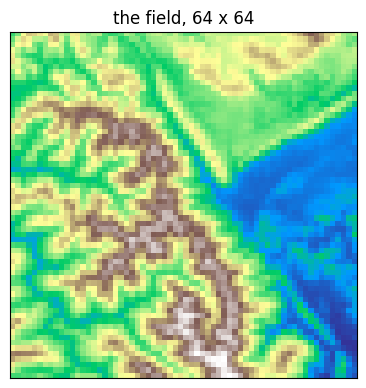

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cbook

N_TRAIN = 64

# Load the file object from Matplotlib's sample data
datafile = cbook.get_sample_data('jacksboro_fault_dem.npz')
dem = np.load(datafile)['elevation']
#dem = cbook.get_sample_data("jacksboro_fault_dem.npz")["elevation"]
crop = dem.astype(float)[40:40 + 256, 60:60 + 256]
block = crop.shape[0] // N_TRAIN
u_grid = crop.reshape(N_TRAIN, block, N_TRAIN, block).mean(axis=(1, 3))
u_grid = (u_grid - u_grid.min()) / np.ptp(u_grid)

print("shape:", u_grid.shape, " stored values:", u_grid.size)

plt.figure(figsize=(4.5, 4.5))
plt.imshow(u_grid, cmap="terrain", vmin=0, vmax=1, interpolation="nearest")
plt.title(f"the field, {N_TRAIN} x {N_TRAIN}")
plt.xticks([]); plt.yticks([])
plt.show()

## 1. A network that takes coordinates

To turn this array into a function we build a training set whose **inputs are the
coordinates of the grid cells** and whose **targets are the field values**.

The helper below returns the centres of the cells of an $n \times n$ grid over the
unit square, as an array of shape $(n^2, 2)$.

In [11]:
def grid_coords(n):
    """The n x n cell centres of the unit square, as an (n*n, 2) array."""
    g = (np.arange(n) + 0.5) / n
    X, Y = np.meshgrid(g, g, indexing="ij")
    return np.stack([X.ravel(), Y.ravel()], axis=1)


print(grid_coords(3))

[[0.16666667 0.16666667]
 [0.16666667 0.5       ]
 [0.16666667 0.83333333]
 [0.5        0.16666667]
 [0.5        0.5       ]
 [0.5        0.83333333]
 [0.83333333 0.16666667]
 [0.83333333 0.5       ]
 [0.83333333 0.83333333]]


<span style="color:blue">Build the training set and fit a multi-layer perceptron on it. Use
<code>MLPRegressor</code> with two hidden layers of 256 units. Note that the target is
a single scalar per sample, so this is an ordinary regression problem &mdash; nothing in
the training procedure itself is specific to this new point of view.</span>

In [12]:
from sklearn.neural_network import MLPRegressor

X_train = grid_coords(N_TRAIN)
y_train = u_grid.ravel()

net = MLPRegressor(hidden_layer_sizes=(256, 256), activation="relu",
                   learning_rate_init=2e-3, max_iter=300,
                   tol=1e-8, n_iter_no_change=60, random_state=0)
net.fit(X_train, y_train)

n_weights = sum(c.size for c in net.coefs_)
print(f"stored values in the array : {u_grid.size:,}")
print(f"weights in the network     : {n_weights:,}")

stored values in the array : 4,096
weights in the network     : 66,304


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:679: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


## 2. Querying at a resolution that was never seen

The network is a function of continuous coordinates, so nothing forces us to evaluate
it on the grid it was trained on. We can ask it for a value *anywhere*.

<span style="color:blue">Evaluate the network on a $256 \times 256$ grid &mdash; four times the
training resolution &mdash; and display the result next to the original array.</span>

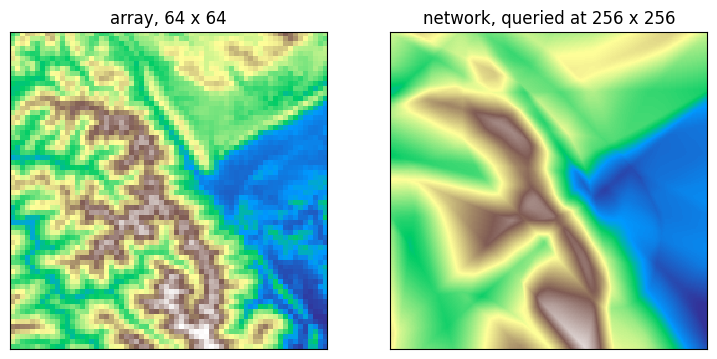

In [13]:
N_QUERY = 256

u_net = net.predict(grid_coords(N_QUERY))
u_net = u_net.reshape(N_QUERY, N_QUERY)

fig, axes = plt.subplots(1, 2, figsize=(9, 4.6))
axes[0].imshow(u_grid, cmap="terrain", vmin=0, vmax=1, interpolation="nearest")
axes[0].set_title(f"array, {N_TRAIN} x {N_TRAIN}")
axes[1].imshow(u_net, cmap="terrain", vmin=0, vmax=1, interpolation="nearest")
axes[1].set_title(f"network, queried at {N_QUERY} x {N_QUERY}")
for a in axes:
    a.set_xticks([]); a.set_yticks([])
plt.show()

<span style="color:blue">The result is continuous, but is it <i>faithful</i>? Compare the ridges
and the valleys of the two images. What has the network lost?</span>

## 3. Spectral bias, and how to get around it

A network fed with raw coordinates fits the **low frequencies** of its target first,
and reaches the high ones extremely slowly &mdash; if ever. This is known as the
*spectral bias* of neural networks, and it is one of the main practical difficulties
of Physics-Informed Neural Networks too.

The standard fix is to stop feeding the raw coordinates, and to project them first
onto a set of sinusoids of random frequencies:
\begin{equation}
    \gamma(\mathbf{x}) = \big[\, \sin(2\pi \mathbf{B}\mathbf{x}),\;
                                  \cos(2\pi \mathbf{B}\mathbf{x}) \,\big]
\end{equation}
where the rows of $\mathbf{B}$ are drawn at random, with a standard deviation that
sets the bandwidth. This is the *Fourier features* trick, and it is the same idea as
the positional encoding of the transformers of lecture 5.

In [22]:
N_FEATS = 128
FEAT_SCALE = 3.0

rng = np.random.default_rng(0)
B = rng.normal(0.0, 1.0, size=(N_FEATS, 2)) * FEAT_SCALE
print("B shape:", B.shape, "stored values:", B.size)

def fourier_features(xy):
    """(n, 2) coordinates -> (n, 2 * N_FEATS) features."""
    proj = 2 * np.pi * xy @ B.T
    return np.concatenate([np.sin(proj), np.cos(proj)], axis=1)


print(fourier_features(grid_coords(3)).shape)

B shape: (128, 2) stored values: 256
(9, 256)


<span style="color:blue">Train the same network on the encoded coordinates, query it again at
$256 \times 256$, and display the three images side by side: the original array, the
network without Fourier features, and the network with them.</span>

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:679: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


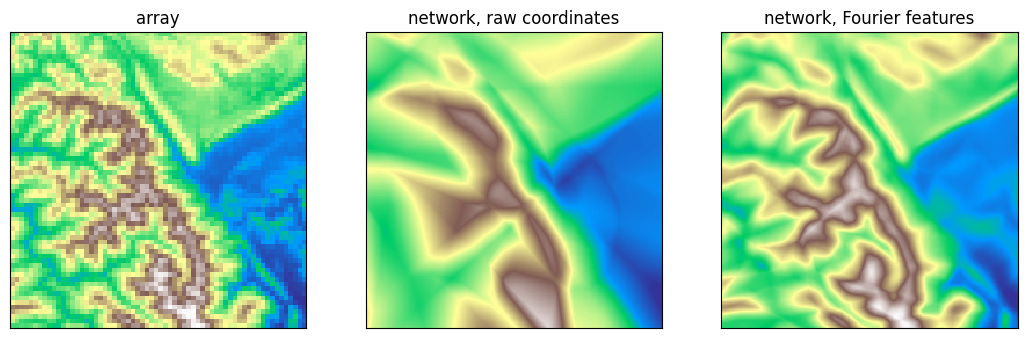

In [21]:
net_ff = MLPRegressor(hidden_layer_sizes=(256, 256), activation="relu",
                      learning_rate_init=2e-3, max_iter=300,
                      tol=1e-8, n_iter_no_change=60, random_state=0)
net_ff.fit(fourier_features(grid_coords(N_TRAIN)), u_grid.ravel())

u_net_ff = net_ff.predict(fourier_features(grid_coords(N_QUERY)))
u_net_ff = u_net_ff.reshape(N_QUERY, N_QUERY)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
for ax, img, title in zip(axes, [u_grid, u_net, u_net_ff],
                          ["array", "network, raw coordinates",
                           "network, Fourier features"]):
    ax.imshow(img, cmap="terrain", vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([])
plt.show()

<span style="color:blue">Re-run the last two cells with <code>FEAT_SCALE = 0.5</code>, then with
<code>FEAT_SCALE = 10.0</code>. Describe what you obtain in each case, and relate it to
the bias-variance trade-off of lecture 1.</span>

## 4. "Defined everywhere" is not a figure of speech

An array only holds values at its nodes. Anything in between has to be interpolated,
and the choice of interpolation scheme is an assumption *we* add afterwards.

The network, on the other hand, answers at any coordinate by construction.

<span style="color:blue">Extract the elevation profile along the diagonal of the domain, sampled
at 500 points, directly from the network. Plot it, and overlay the 64 values that the
array can provide along the same line.</span>

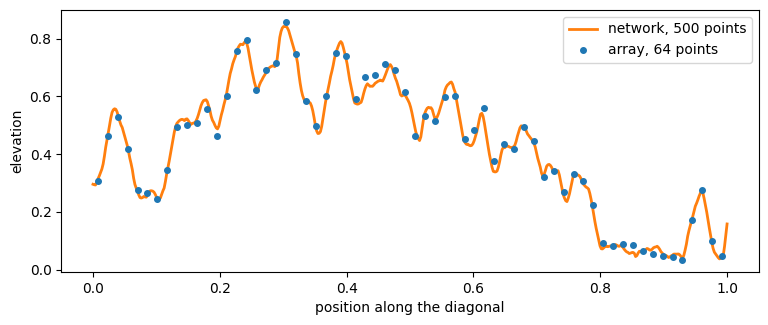

In [16]:
t = np.linspace(0, 1, 500)
line_xy = np.stack([t, t], axis=1)
profile = net_ff.predict(fourier_features(line_xy))

# what the array can give along the same diagonal, without interpolating
k = np.arange(N_TRAIN)
profile_grid = u_grid[k, k]

plt.figure(figsize=(9, 3.4))
plt.plot(t, profile, color="C1", lw=2, label="network, 500 points")
plt.plot((k + 0.5) / N_TRAIN, profile_grid, "o", ms=4, color="C0",
         label=f"array, {N_TRAIN} points")
plt.xlabel("position along the diagonal"); plt.ylabel("elevation")
plt.legend(); plt.show()

<span style="color:blue">Now take a line that does <b>not</b> follow the grid, for instance from
$(0.1, 0.8)$ to $(0.9, 0.25)$, and plot the profile the network gives. What would you
have had to do to obtain the same thing from the array alone?</span>

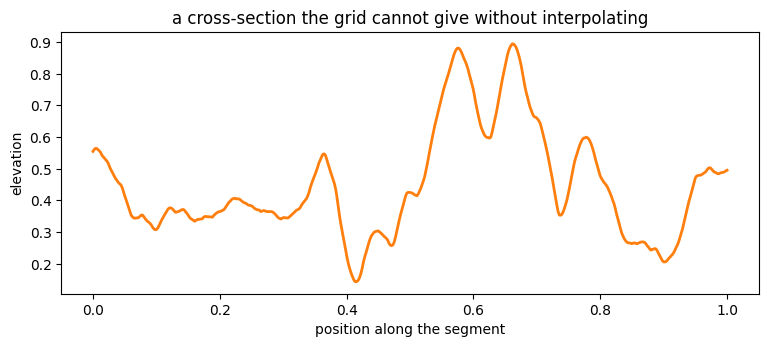

In [17]:
a, b = np.array([0.1, 0.8]), np.array([0.9, 0.25])
line_xy = a + np.outer(t, b - a)
profile = net_ff.predict(fourier_features(line_xy))

plt.figure(figsize=(9, 3.4))
plt.plot(t, profile, color="C1", lw=2)
plt.xlabel("position along the segment"); plt.ylabel("elevation")
plt.title("a cross-section the grid cannot give without interpolating")
plt.show()

## 5. From a representation to a solver

So far we have stored a field that we already knew. The whole point of what comes next
is that the same object can be used when the field is **unknown**.

The network is a differentiable function of its inputs, so $\partial u_\theta /
\partial x$ and $\partial^2 u_\theta / \partial x^2$ can be obtained *exactly*, by
automatic differentiation &mdash; the same mechanism as in lecture 3, but applied to
the inputs instead of the weights. We can therefore evaluate the residual of a partial
differential equation at any point of the domain, **without knowing its solution**.

Fitting the network to an *equation* rather than to *values* is exactly what a
Physics-Informed Neural Network does, and it is the subject of the next notebook.

<span style="color:blue">Scikit-learn gives no access to the derivatives of a fitted
<code>MLPRegressor</code> with respect to its inputs. Which of the tools seen in
lecture 3 would you need instead, and why is it indispensable here?</span>